In [ ]:
print("Email Spam Classification Assignment")
print("Fresh notebook is working!")

Email Spam Classification Assignment
Fresh notebook is working!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower().endswith(('.xlsx', '.xls', '.csv')):
            print(os.path.join(root, file))

/content/drive/MyDrive/emails.csv
/content/drive/MyDrive/NPN Registration List (7) (1).xlsx
/content/drive/MyDrive/NPN Registration List (7).xlsx


In [ ]:
import pandas as pd



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for name in files:
        if name.lower().endswith(('.xlsx', '.xls', '.csv')):
            print(os.path.join(root, name))

/content/drive/MyDrive/emails.csv
/content/drive/MyDrive/NPN Registration List (7) (1).xlsx
/content/drive/MyDrive/NPN Registration List (7).xlsx


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/emails.csv'
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [ ]:
print("First 10 column names:")
print(df.columns[:10].tolist())

print("\nLast 5 column names:")
print(df.columns[-5:].tolist())

print("\nMissing values:", df.isnull().sum().sum())

First 10 column names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou']

Last 5 column names:
['military', 'allowing', 'ff', 'dry', 'Prediction']

Missing values: 0


In [ ]:
from sklearn.model_selection import train_test_split

# Remove duplicate rows
df = df.drop_duplicates()

# The final column is assumed to be the spam label.
# The first column is assumed to be an email ID.
X = df.iloc[:, 1:-1].apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(df.iloc[:, -1], errors='coerce')

# Remove rows with missing labels
valid = y.notna()
X = X.loc[valid].fillna(0)
y = y.loc[valid].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nSpam label counts:")
print(y.value_counts())

Features shape: (5172, 3000)
Target shape: (5172,)

Spam label counts:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4137
Testing samples: 1035


***Train the KNN and SVM models***

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

models = {
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(random_state=42, max_iter=10000)
    )
}

results = []
predictions = {}

for name, model in models.items():
    print(f"\nTraining {name} model...")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

    print(f"\n{name} Classification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

print("\nBoth models trained successfully!")


Training KNN model...

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


Training SVM model...

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.95       735
           1       0.84      0.96      0.89       300

    accuracy                           0.93      1035
   macro avg       0.91      0.94      0.92      1035
weighted avg       0.94      0.93      0.94      1035


Both models trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


***Compare the performance***

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.8338,0.6435,0.9567,0.7694
1,SVM,0.9343,0.8392,0.9567,0.8941


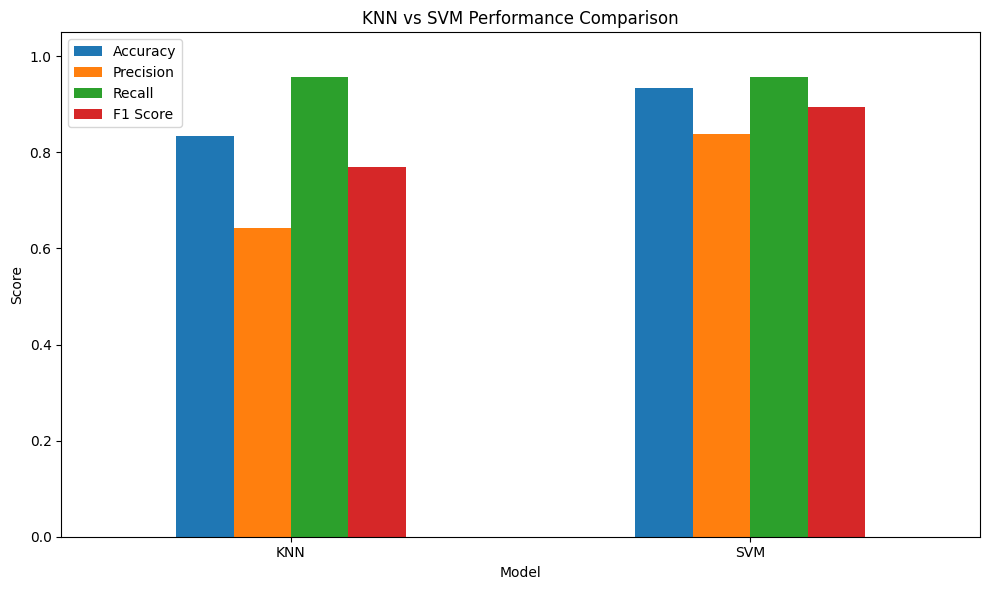

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(4))

# Save results to Google Drive
results_df.to_csv(
    '/content/drive/MyDrive/email_spam_model_comparison.csv',
    index=False
)

# Plot comparison
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("KNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/email_spam_model_comparison.png',
    dpi=300
)
plt.show()

***Generate confusion matrices***

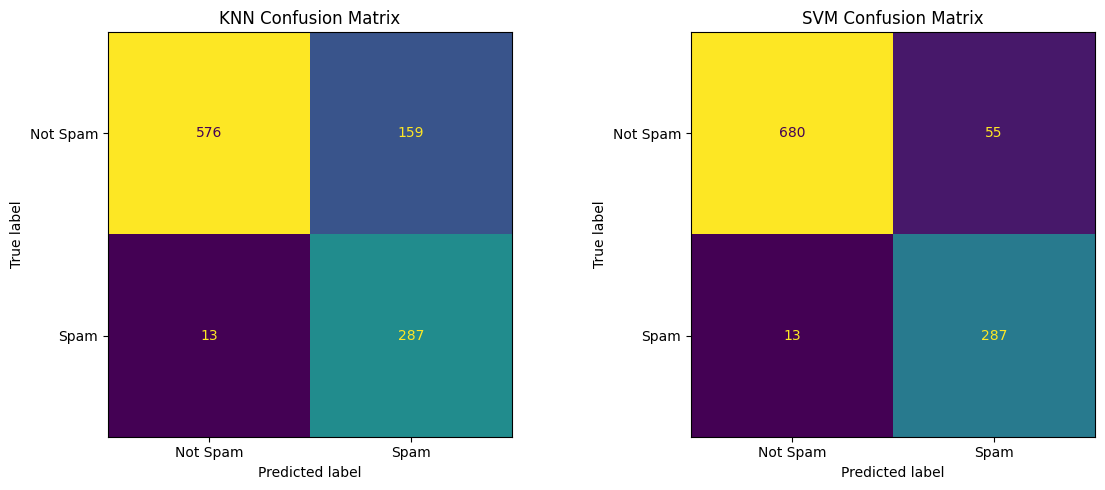

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, models.keys()):
    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Spam", "Spam"]
    )

    display_cm.plot(ax=ax, colorbar=False)
    ax.set_title(f"{name} Confusion Matrix")

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/email_spam_confusion_matrices.png',
    dpi=300
)
plt.show()

***The final conclusion***

In [ ]:
best_model = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

print("FINAL COMPARISON")
display(results_df.round(4))

print("\nCONCLUSION")
print(
    f"{best_model} achieved the highest F1 score on the test dataset. "
    "Both KNN and SVM were evaluated using accuracy, precision, "
    "recall, F1 score, and confusion matrices."
)

print("\nFiles saved in Google Drive:")
print("1. email_spam_model_comparison.csv")
print("2. email_spam_model_comparison.png")
print("3. email_spam_confusion_matrices.png")

FINAL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.8338,0.6435,0.9567,0.7694
1,SVM,0.9343,0.8392,0.9567,0.8941



CONCLUSION
SVM achieved the highest F1 score on the test dataset. Both KNN and SVM were evaluated using accuracy, precision, recall, F1 score, and confusion matrices.

Files saved in Google Drive:
1. email_spam_model_comparison.csv
2. email_spam_model_comparison.png
3. email_spam_confusion_matrices.png
